# Lab 7: new CFD at the four high-Re Ghia cases

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week04/W4_Lab7_High_Re_CFD_Ghia.ipynb)

**Question:** what changes when we actually solve the cavity at $Re=3200,5000,7500,10000$?
This lab reads newly computed full CFD fields on **128, 256 and 512 cells per side**.
It follows Lab 5 (benchmark/reference policy) and Lab 6 (the separate profile neural network).
The existing low-Re lessons and frozen neural fits are preserved.

Run All audits the saved results on a CPU. It does not submit HPC jobs or retrain a model.
The solver and production command are provided below for deliberate reproduction.

[Protocol and equations](../../docs/CAVITY_HIGH_RE_PROTOCOL.md) ·
[Native fields, figures and provenance](../../results/cavity_highre_ghia/README.md) ·
[Week 4 lecture](../../lectures/week04_cavity_surrogates_deeponet.pdf)

## 1. Physical and numerical problem

A unit square has a lid moving at $U=1$ and stationary no-slip other walls.
The discontinuity at the two upper corners is retained. Define $Re=UL/\nu$,
$u=\partial_y\psi$, $v=-\partial_x\psi$, and $\omega=\partial_xv-\partial_yu$.
The two steady equations are

$$\nabla^2\psi+\omega=0,\qquad
\frac{1}{Re}\nabla^2\omega-u\partial_x\omega-v\partial_y\omega=0.$$

Central differences and Thom wall vorticity match the existing Week-4 spatial
formulation. Damped Newton solves the steady equations with an analytical
Jacobian; continuation in Re supplies an initial state. **No Ghia values enter
these PDE solves.** Newton iteration count is not physical time.

A small equation residual establishes a discrete root. It does not establish
mesh independence, long-time stability or a three-dimensional physical flow.
We do not reconstruct pressure in this extension.

## Aim and route through this lab

**Aim.** Qualify the high-Reynolds CFD fields before using them as neural labels.
Re=3200,5000,7500,10000 are represented on 128,256,512-cell grids. The notebook
loads native arrays and verifies hashes, equations, walls and centreline
comparisons. Run All audits completed numerical evidence on CPU; it does not
launch those large solves again.

Sections 2–3 show the actual flow and the published Ghia samples. Section 4
compares nested native grids: signed velocity changes locate where refinement
matters, and signed streamfunction contours expose weak corner vortices that
a whole-domain view may miss. Section 5 is a distinct short-time perturbation
and time-step check. A steady Newton residual does not prove that a steady
solution is dynamically stable at high Re.

Sections 6–7 explain deliberate reproduction and specific engineering tasks.
The final solver appendix compares a sparse-direct Newton solve with a
GMRES/multigrid candidate at matched accepted discrete solutions. Fewer linear
iterations did not imply lower total time because setup dominated. Keep this
CFD solver experiment separate from a neural optimizer experiment.

**Required evidence:** all/screened Ghia errors, signed mesh differences,
corner-flow contours, short-time sensitivity, and an explicit decision about
which uncertainty remains. Read the Lab 7 and solver-cost sections of
[Lecture 4](../../lectures/week04_cavity_surrogates_deeponet.pdf).


In [1]:
from pathlib import Path
import sys, subprocess
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1','https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file():
        raise RuntimeError('This checkout predates the cavity extension. Use an updated FlowMLLab checkout after saving your student work; do not overwrite your edited notebook.')
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from flowmllab import ghia, cavity_course as course

from flowmllab import cavity_highre as high
if not (ROOT/'results/cavity_highre_ghia/n512/re10000.npz').is_file():
    raise RuntimeError('Use a complete FlowMLLab v1.13.0 or newer checkout; the original low-Re bundle is insufficient.')
cases = high.load_cases(ROOT)  # SHA256, PDE, boundaries and continuity
scores = pd.DataFrame(high.score_rows(cases))
print(f'Independently checked {len(cases)} actual CFD fields.')
display(scores[['Re','cells','steady_vorticity_linf','poisson_linf','continuity_linf']])

# Shared, array-driven figures; student outputs stay separate from frozen evidence.
from pathlib import Path
import os, sys
_w4_root = next(p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
                if (p/'flowmllab/week04_teaching_plots.py').is_file())
if str(_w4_root) not in sys.path: sys.path.insert(0, str(_w4_root))
from flowmllab import week04_teaching_plots as w4plots
W4_OUTPUT = Path(os.environ.get('FLOWMLLAB_W4_OUTPUT', str(_w4_root/'student_outputs/week04_current')))
W4_OUTPUT.mkdir(parents=True, exist_ok=True)
def save_current_figure(fig, name):
    fig.savefig(W4_OUTPUT/(name+'.png'), dpi=150, bbox_inches='tight')
    return fig


Independently checked 12 actual CFD fields.


,Re,cells,steady_vorticity_linf,poisson_linf,continuity_linf
0,3200,128,2.047784e-10,1.881384e-12,7.105427e-15
1,3200,256,5.615561e-10,8.020029e-12,1.421085e-14
2,3200,512,4.920011e-10,3.244716e-11,2.842171e-14
3,5000,128,2.202327e-10,1.775247e-12,7.105427e-15
4,5000,256,1.077410e-09,7.685186e-12,1.421085e-14
5,5000,512,9.625865e-10,3.140133e-11,2.842171e-14
6,7500,128,5.559784e-10,1.810108e-12,7.105427e-15
7,7500,256,3.613231e-09,7.704504e-12,1.421085e-14
8,7500,512,7.270160e-09,3.140821e-11,2.842171e-14
9,10000,128,5.133813e-10,1.809441e-12,3.552714e-15


## 2. Look at the physical flow first

The black curves below are streamlines of the newly calculated finest-grid
velocity. Compare the primary vortex and the corner recirculations as Re grows.
A weak small vortex may be poorly represented by automatic streamline seeding:
inspect streamfunction contours in the exercise, rather than inferring absence
from an empty-looking corner.

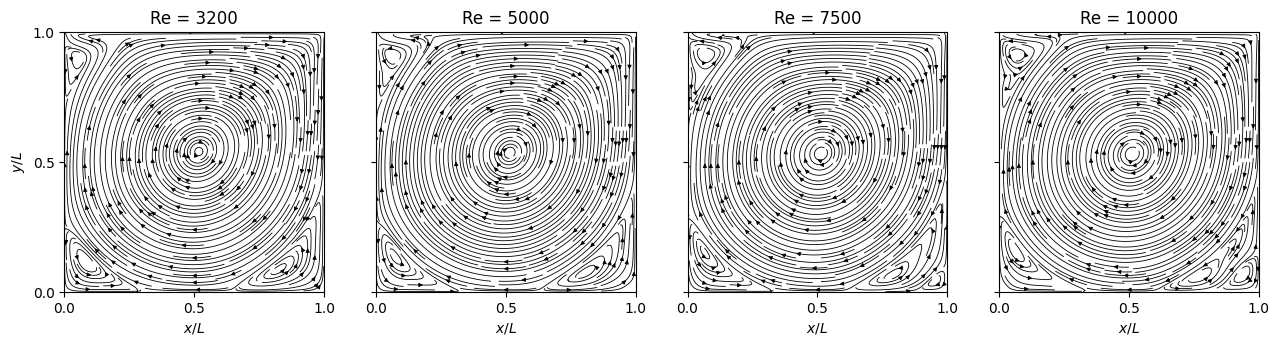

In [2]:
fig = high.plot_streamlines(cases)
plt.show()

## 3. All four new comparisons with Ghia

Each panel contains our three independently converged CFD grids and the original
published samples. The cross retains a previously flagged printed entry: the
$u/U=-0.86636$ point at $Re=3200, y/L=0.4531$, or $+0.03111$ at
$Re=10000, y/L=0.5$. These are a sensitivity policy, not a claimed erratum.
We show both all-point and screened metrics below. Nothing is silently deleted.

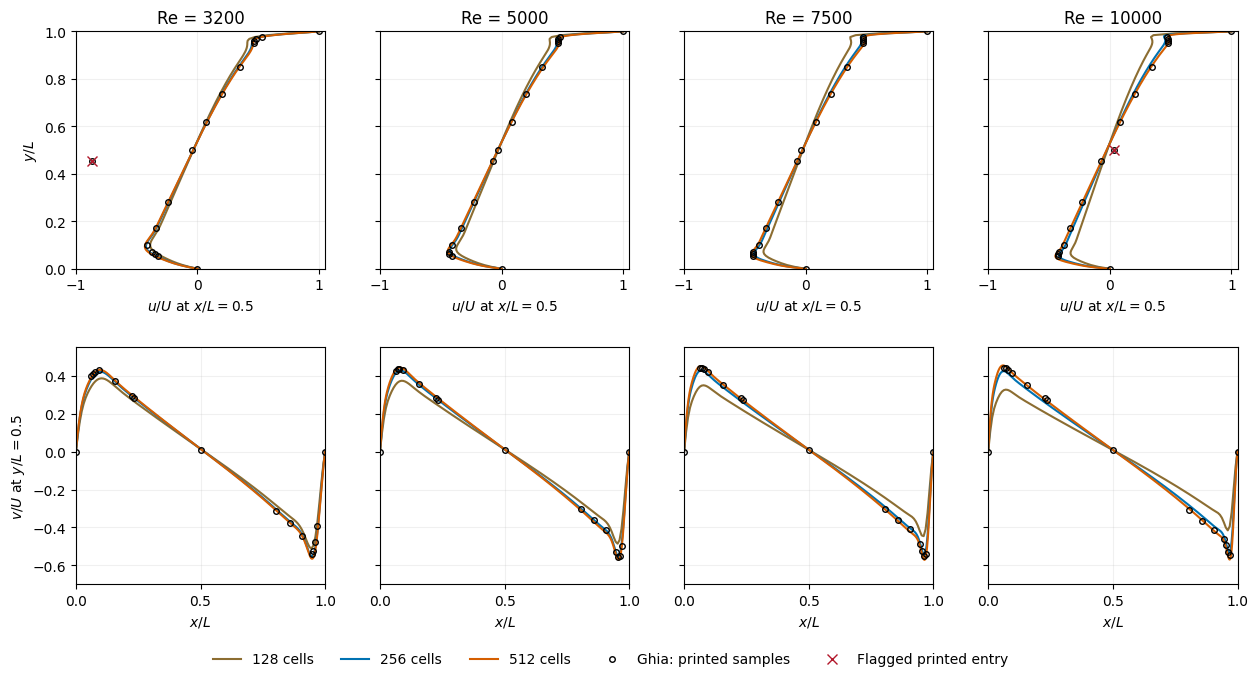

,Re,u_published_relative_l2,u_screened_relative_l2,v_published_relative_l2,v_screened_relative_l2,u_screened_rmse_U,v_screened_rmse_U
2,3200,0.415516,0.030394,0.047732,0.047732,0.012802,0.017788
5,5000,0.016099,0.016099,0.021369,0.021369,0.006653,0.008279
8,7500,0.018221,0.018221,0.022401,0.022401,0.007566,0.008635
11,10000,0.039547,0.020584,0.025240,0.025240,0.008806,0.009576


In [3]:
fig = high.plot_overview(cases)
plt.show()
finest_scores = scores[scores.cells==512].copy()
display(finest_scores[['Re','u_published_relative_l2','u_screened_relative_l2',
                      'v_published_relative_l2','v_screened_relative_l2',
                      'u_screened_rmse_U','v_screened_rmse_U']])

For a chosen Re, inspect the flow and both centreline profiles at a larger size.
Change `RE_TO_INSPECT` to any one of the four values; do not alter the reference data.

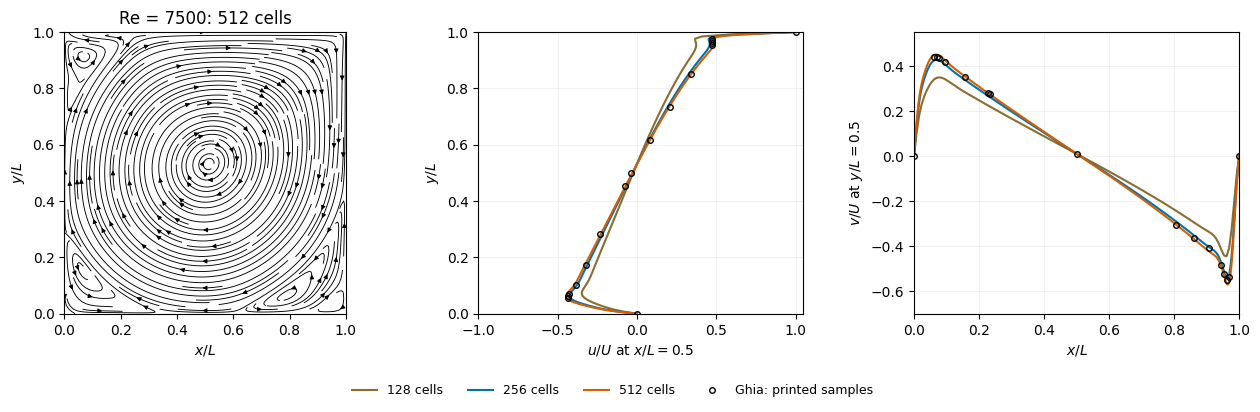

In [4]:
RE_TO_INSPECT = 7500
fig = high.plot_case(cases, RE_TO_INSPECT)
plt.show()

## 4. How much does the mesh still change the answer?

The following table compares the 128- and 256-cell profiles with the 512-cell
profile at the same 2049 evaluation locations. This dense interpolation is only
for comparing CFD curves; it does not manufacture more Ghia observations.
RMSE and maximum differences are normalized by lid speed, with signs retained
in the profile plots. Do not equate the smallest Ghia error with the best mesh:
the benchmark table has its own numerical error and sparse coverage.

In [5]:
mesh = pd.DataFrame(high.mesh_rows(cases))
display(mesh)
# Native values at fixed positions, evaluated in the same way on each mesh.
positions = np.array([0.05, 0.10, 0.50, 0.90, 0.95])
samples = []
for case in cases:
    for component in ('u','v'):
        values = np.interp(positions, *case['profiles'][component])
        samples.extend(dict(Re=case['Re'], cells=case['cells'], component=component,
                            position=float(t), velocity_U=float(q))
                       for t,q in zip(positions,values))
sample_table = pd.DataFrame(samples)
display(sample_table[sample_table.Re==RE_TO_INSPECT])

,Re,cells,reference_cells,velocity_relative_l2,velocity_vector_rms_U,velocity_component_linf_U,u_rmse_U,u_linf_U,v_rmse_U,v_linf_U
0,3200,128,512,0.093311,0.028870,0.291035,0.026156,0.053769,0.026999,0.069897
1,3200,256,512,0.020252,0.006215,0.165595,0.005477,0.011273,0.005631,0.015020
2,5000,128,512,0.144281,0.044688,0.362017,0.040475,0.083131,0.041632,0.110038
3,5000,256,512,0.031444,0.009656,0.201149,0.008652,0.017735,0.008845,0.023754
4,7500,128,512,0.209790,0.064807,0.432043,0.058442,0.119384,0.059995,0.162119
5,7500,256,512,0.047195,0.014447,0.248111,0.013025,0.026665,0.013268,0.036192
6,10000,128,512,0.265019,0.081513,0.521088,0.073232,0.148875,0.075121,0.201880
7,10000,256,512,0.063226,0.019260,0.290762,0.017355,0.035421,0.017650,0.048214


,Re,cells,component,position,velocity_U
60,7500,128,u,0.05,-0.314325
61,7500,128,u,0.10,-0.323586
62,7500,128,u,0.50,-0.024167
63,7500,128,u,0.90,0.325945
64,7500,128,u,0.95,0.372904
65,7500,128,v,0.05,0.319153
66,7500,128,v,0.10,0.336495
67,7500,128,v,0.50,0.009285
68,7500,128,v,0.90,-0.331002
69,7500,128,v,0.95,-0.432207


### Locate the mesh discrepancy in physical space

This figure implements the comparison needed before declaring a grid sufficient.
The finest retained CFD field is the reference for this **mesh-sensitivity**
check, not an exact solution. The upper-left region is not inferred from a
global error: inspect its signed streamfunction levels on each native grid.
The whole-domain and corner panels use identical physical contour levels for
all grids; solid, dashed and dotted lines distinguish the grids.


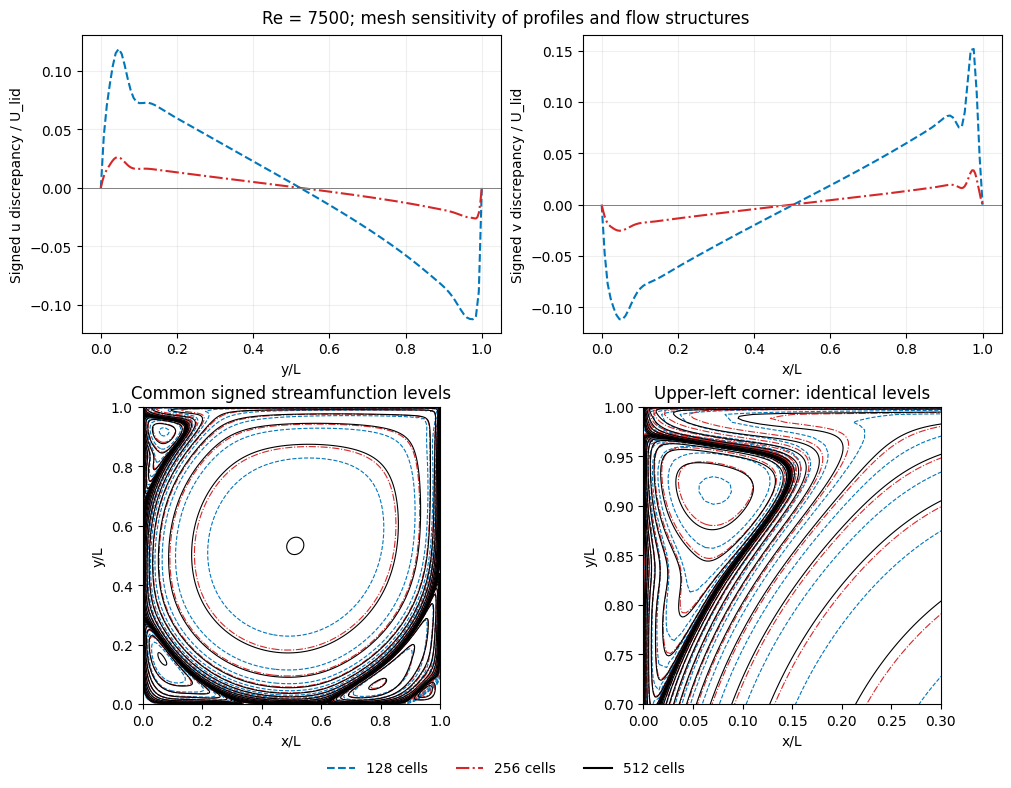

In [6]:
subset = sorted([c for c in cases if c['Re']==RE_TO_INSPECT],key=lambda c:c['cells'])
fine = subset[-1]
fig, axes = plt.subplots(2,2,figsize=(10,7.8),layout='constrained')
for case, style, color in zip(subset[:-1], ('--','-.'), ('#0077bb','#d62728')):
    for ax, component in zip(axes[0], ('u','v')):
        position, coarse = case['profiles'][component]
        reference = np.interp(position,*fine['profiles'][component])
        ax.plot(position, coarse-reference,ls=style,color=color,
                label=f"{case['cells']} minus {fine['cells']} cells")
        ax.set(xlabel='y/L' if component=='u' else 'x/L',ylabel=f'Signed {component} discrepancy / U_lid')
for ax in axes[0]: ax.axhline(0,color='.5',lw=.7); ax.grid(alpha=.2)
levels = np.r_[-np.geomspace(.00001,.12,15)[::-1], np.geomspace(.000001,.003,12)]
for case, style, color in zip(subset, ('--','-.','solid'), ('#0077bb','#d62728','black')):
    f=case['field']
    for ax in axes[1]:
        ax.contour(f['x'],f['y'],f['psi'],levels=levels,colors=color,linestyles=style,linewidths=.8)
        ax.set(xlabel='x/L',ylabel='y/L',aspect='equal')
axes[1,0].set(xlim=(0,1),ylim=(0,1),title='Common signed streamfunction levels')
axes[1,1].set(xlim=(0,.3),ylim=(.7,1),title='Upper-left corner: identical levels')
from matplotlib.lines import Line2D
handles = [Line2D([],[],color=color,ls=style,label=f"{c['cells']} cells")
           for c,style,color in zip(subset,('--','-.','solid'),('#0077bb','#d62728','black'))]
fig.legend(handles=handles,loc='outside lower center',ncol=3,frameon=False)
fig.suptitle(f'Re = {RE_TO_INSPECT}; mesh sensitivity of profiles and flow structures')
save_current_figure(fig, f'lab7_Re{RE_TO_INSPECT}_mesh_profiles_corners');plt.show();plt.close(fig)


## 5. Physical time is a separate test

On 256 cells, both time steps ($0.002$ and $0.001$) start from the same steady
field plus $\delta\psi=10^{-4}\sin^2(\pi x)\sin^2(\pi y)$.
Vorticity is changed consistently by $\delta\omega=-\nabla_h^2\delta\psi$.
SSPRK3 uses a fresh Poisson and wall-vorticity solve at every stage.
The observation times match exactly from $tU/L=0$ to $10$.

The paired trajectory difference tests time discretization. Growth or decay over
this short interval **does not settle asymptotic stability**, and this single
perturbation does not probe every possible mode. In particular, a steady Newton
root at Re=10000 is not evidence of stable physical flow.

,Re,cells,time_end,dt_coarse,dt_fine,paired_velocity_rms_difference_U,paired_velocity_linf_difference_U,relative_perturbation_difference,initial_departure_rms_U,final_departure_rms_U,finite_horizon_growth,finite_horizon_time_check_pass
0,3200,256,10,0.002,0.001,1.070748e-12,2.948752e-12,6.873451e-09,0.000192,0.000156,0.812987,True
1,5000,256,10,0.002,0.001,2.234917e-12,6.661283e-12,1.325910e-08,0.000192,0.000169,0.879667,True
2,7500,256,10,0.002,0.001,8.731586e-12,4.324574e-11,4.847611e-08,0.000192,0.000180,0.940019,True
3,10000,256,10,0.002,0.001,2.570625e-11,1.632892e-10,1.234108e-07,0.000192,0.000208,1.087068,True


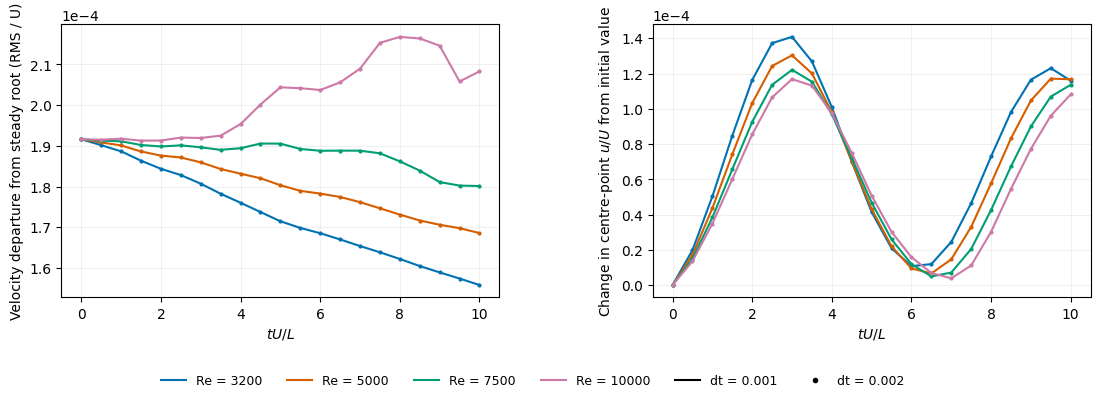

In [7]:
time_rows, time_pairs = high.load_temporal(ROOT)
time_table = pd.DataFrame(time_rows)
display(time_table)
fig = high.plot_temporal(time_pairs)
plt.show()

## 6. Reproduce a solver run deliberately

The CPU production entry point is `qa/run_cavity_highre.py`; it stores one
configuration-matched complete continuation checkpoint and the four target
fields. It requires NumPy and SciPy. The 512-cell sparse factorizations are more
expensive than the default notebook audit; do not launch them by accident.

```bash
python qa/run_cavity_highre.py --cells 256 \
  --seed results/week01_2_formulations/streamfunction-vorticity-re1000-n128.npz \
  --output /your/allocated/scratch/cavity-highre
```

For Unity, allocate/discover the actual Workspace first. The retained batch
script records this campaign's real scratch path; replace that path with your
own allocated path when reproducing. The saved metadata includes source hashes,
seed identity, all continuation trials, convergence and runtime. The initial
failed direct 1000-to-3200 Newton jump is documented in the protocol.

## 7. Engineering exercises and required deliverables

**Exercise A — compute, do not just inspect.** For every Re, report the finest-grid
u and v RMSE/U, all-point relative L2 error, screened relative L2 error, and the
number of excluded reference points. Use `scores` from Section 3. Explain
numerically why the two Re=3200 u metrics differ. Do not hide the printed sample.

**Exercise B — mesh decision.** From the Section 4 `mesh` table, compare 128-to-512
and 256-to-512 RMSE and maximum errors. For each component/Re, state whether a
1% of U maximum-profile-change requirement is met by the 256-cell mesh. Use the
actual numbers; a failed requirement is a valid result. On two separate axes,
plot the signed 256-minus-512 u and v differences against centreline position.
Explain why this is a sensitivity check rather than a formal Richardson estimate.

**Exercise C — secondary vortices.** For Re=3200 and 10000 on all three grids,
plot signed streamfunction contours in the bottom-right square
$0.65\le x/L\le1$, $0\le y/L\le0.35$. Report the maximum positive streamfunction
and its coordinates in that region. Show whether refinement shifts or changes
the secondary vortex. Supply one physical contour plot, not a bar chart.

**Exercise D — time and convergence.** From the Section 5 `time_table`, report the
paired RMS difference and final/initial perturbation RMS for all four Re.
Identify the largest short-time growth and the largest time-step discrepancy.
Explain why tiny Newton residuals and a small dt discrepancy do not prove
long-time stability. Design a further test with a longer window, a finer spatial
grid and more than one perturbation; distinguish your design from a completed run.

**Exercise E — honest machine learning.** Read the frozen split and scores in
Lab 6. Explain the difference between its centreline-data MLP and a full-field
supervised operator trained on these new CFD fields; a data-free PINN uses PDE
residuals instead of CFD labels. Lab 8 supplies the actual full-field experiment. List what information the latter
would see, which whole Re cases would be withheld, and what independent fields
and equation checks you would use. Re=3200 and 7500 tests from Lab 6 are already
disclosed; tuning against them requires a fresh test for a new research claim.
Compare the Lab 8 validation and test tables with your design. Keep its
supervised neural results distinct from the CFD evidence in this notebook.

Submit: one numerical table for A/B/D, the signed profile plot for B, the physical
corner-vortex comparison for C, and a concise interpretation for D/E. Include
source version and native field hashes so the results are traceable.

## 8. A measured solver experiment: fewer iterations, more time

**Engineering decision: retain our existing sparse-direct Newton solver for these cases.**
We tested a more elaborate linear solver rather than assuming that it would be faster.
Its warm-case time was **1.95-2.17 times the direct solver time**, while the accepted
fields agreed to numerical precision. This is a useful negative result: it prevents
repeating an expensive unsuccessful configuration and identifies what must change
before another attempt is worthwhile.

This appendix uses the completed, frozen experiment of 15 November 2026.
**Run All reanalyzes stored data on CPU; it does not run CFD, submit jobs or train a network.**
The [full evidence and report](../../results/cavity_solver_benchmark/README.md),
[experimental solver](../../flowmllab/cavity_krylov.py), and
[trial driver](../../qa/benchmark_cavity_solvers.py) preserve the successful and failed trials.
The corresponding discussion is at the end of the
[Week 4 lecture](../../lectures/week04_cavity_surrogates_deeponet.pdf).

### 8.1 What changed, and what stayed fixed?

The discrete cavity equations define a residual $F(q)=0$, where
$q=[\psi,\omega]^T$ contains the interior streamfunction and vorticity unknowns.
At Newton step $k$ we solve

$$J(q_k)\,\Delta q_k=-F(q_k),\qquad q_{k+1}=q_k+\alpha_k\Delta q_k.$$

Here $J=\partial F/\partial q$ is the same analytical Jacobian, $\Delta q_k$ the
Newton correction, and $0<\alpha_k\le1$ the existing line-search step.
The baseline factors the sparse $J$ directly. The candidate uses GMRES
(a Krylov iterative linear solver) with a coupled geometric Galerkin multigrid
V-cycle as preconditioner. A preconditioner is an approximate inverse used to
make the linear iteration easier; it also costs time to construct and apply.

The V-cycle uses bilinear prolongation, scaled-transpose restriction, and ILUT
(incomplete LU with threshold dropping) before and after coarse-grid correction.
The coarsest problem is solved directly. Invertible variable scaling and row
scaling balance variable and equation scales before the iterative solve; acceptance is checked again
in the **original, unscaled equations**. This is a CFD linear-solver experiment,
not a neural-network optimizer experiment.

The PDE, walls, grids, seed fields, precision, Jacobian, outer Newton algorithm
and final acceptance checks are unchanged. The final residual must be below
$10^{-8}$ in maximum norm, and velocity/vorticity must agree with the retained
same-grid CFD within relative $L_2$ limits $10^{-8}$ and $10^{-7}$.
**Inner tolerances are not identical:** the unchanged outer linear-defect gate is
$10^{-5}$; the candidate additionally requires an original-equation linear defect
at most $10^{-7}$, with internal GMRES relative tolerance $10^{-9}$.
We did not loosen the final criterion to make a method appear faster.

### 8.2 A matched timing protocol

Each trial used one CPU thread on the same Intel Xeon Gold 5220 node, with
Python 3.12.3, NumPy 2.2.6 and SciPy 1.15.3. Paired methods ran sequentially;
the two grid studies occupied separate cores on the same allocation.
There were three warm repetitions with method order **AB, BA, AB**, where A is
direct and B is GMRES/multigrid. Both methods start from the same stored
$Re=6500$ field for the $Re=7500$ target, or the same $Re=9000$ field for $Re=10000$.
These are **warm continuation steps, not cold-start solves**.

The separate 257-by-257-node continuation comparison starts from one retained
129-by-129-node $Re=1000$ field, interpolates it identically, and follows the same
20-root path from $Re=1000$ to $10000$. It has **one repetition per method**.
No full 513-by-513-node continuation comparison is claimed.

Solve wall time includes Jacobian assembly and all preconditioner construction.
It excludes queuing, imports, initial I/O, seed generation, verification and
checkpoint writing. The following cells recompute medians and ratios from the
individual run records rather than trusting a transcribed table.

In [8]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image

# Independent of neural-model imports; also runs from a notebook subdirectory.
bench_candidates = [Path(p) for p in [globals().get('ROOT'), Path.cwd(),
                    *Path.cwd().parents, Path('/content/FlowMLLab')] if p is not None]
bench_root = next((p for p in bench_candidates
                   if (p/'results/cavity_solver_benchmark/manifest.json').is_file()), None)
if bench_root is None:
    raise FileNotFoundError('Use the complete updated FlowMLLab checkout.')
BENCH = bench_root/'results/cavity_solver_benchmark'
bench_manifest = json.loads((BENCH/'manifest.json').read_text(encoding='utf-8-sig'))
for name, expected in bench_manifest['sha256'].items():
    assert hashlib.sha256((BENCH/name).read_bytes()).hexdigest() == expected, name
bench_evidence = json.loads((BENCH/'evidence.json').read_text(encoding='utf-8-sig'))
bench_trials = bench_evidence['trials']
production_trials = [e['result'] for e in bench_trials if e['path'].startswith('production/')]
assert len(production_trials) == 26

# Match inputs and numerical policy BEFORE calculating a performance ratio.
identity_keys = ['seed_sha256', 'reference_sha256', 'packed_initial_state_sha256',
                 'host', 'slurm_job_id', 'environment', 'thread_environment',
                 'schedule', 'nonlinear_tolerance', 'source_sha256_lf', 'candidate_config']
paired_runs = {}
for run in production_trials:
    key = (run['cells'], run['scenario'], run['repeat'])
    paired_runs.setdefault(key, {})[run['method']] = run
assert len(paired_runs) == 13
for key, pair in paired_runs.items():
    assert set(pair) == {'direct', 'gmres_mg'}, key
    direct, mg = pair['direct'], pair['gmres_mg']
    for name in identity_keys:
        assert direct[name] == mg[name], (key, name)
    for run in (direct, mg):
        assert run['success'] and run['final_residual_linf'] < 1e-8
        assert set(run['thread_environment'].values()) == {'1'}
        assert run['reference_discrepancies']['velocity_relative_l2'] < 1e-8
        assert run['reference_discrepancies']['omega']['relative_l2'] < 1e-7
        assert all(s['success'] and s['original_relative_defect'] <= 1e-5
                   for s in run['linear_solves'])

# One row per actual run; never put failed pilot runs in successful timing medians.
trial_timing = pd.DataFrame([{
    'nodes': run['nodes'], 'scenario': run['scenario'], 'method': run['method'],
    'repeat': run['repeat'], 'wall_s': run['solve_wall_seconds'],
    'setup_s': run['profiling']['preconditioner_setup_seconds'],
    'newton_steps': sum(h['newton_iterations'] for h in run['history']),
    'gmres_iterations': run['profiling']['krylov_iterations'],
    'peak_rss_MiB': run['peak_rss_KiB']/1024,
} for run in production_trials])
bench_timing = trial_timing.groupby(['nodes', 'scenario', 'method']).agg(
    repetitions=('wall_s', 'size'), median_s=('wall_s', 'median'),
    minimum_s=('wall_s', 'min'), maximum_s=('wall_s', 'max'),
    setup_median_s=('setup_s', 'median'),
    newton_steps_median=('newton_steps', 'median'),
    gmres_iterations_median=('gmres_iterations', 'median'),
    peak_rss_MiB=('peak_rss_MiB', 'max')).reset_index()
bench_comparison = bench_timing.pivot(index=['nodes', 'scenario'], columns='method', values='median_s')
bench_comparison['MG_over_direct'] = bench_comparison.gmres_mg / bench_comparison.direct
bench_comparison.columns.name = None
print('Verified evidence-file hashes and recorded input hashes/pair identity for 13 pairs (26 successful main trials).')
display(bench_timing[['nodes', 'scenario', 'method', 'repetitions', 'median_s', 'minimum_s', 'maximum_s']])
display(bench_comparison)

Verified evidence-file hashes and recorded input hashes/pair identity for 13 pairs (26 successful main trials).


,nodes,scenario,method,repetitions,median_s,minimum_s,maximum_s
0,257,continuation,direct,1,247.442013,247.442013,247.442013
1,257,continuation,gmres_mg,1,561.950467,561.950467,561.950467
2,257,warm10000,direct,3,14.854675,14.522826,15.257235
3,257,warm10000,gmres_mg,3,28.998392,28.540719,29.298747
4,257,warm7500,direct,3,14.247829,14.223867,14.679699
5,257,warm7500,gmres_mg,3,29.270279,29.228729,29.543665
6,513,warm10000,direct,3,133.804384,133.435665,136.642175
7,513,warm10000,gmres_mg,3,273.300556,269.880109,273.741709
8,513,warm7500,direct,3,130.157873,127.245380,134.147537
9,513,warm7500,gmres_mg,3,283.005024,279.991094,293.303689


direct    gmres_mg  MG_over_direct
nodes scenario                                            
257   continuation  247.442013  561.950467        2.271039
      warm10000      14.854675   28.998392        1.952139
      warm7500       14.247829   29.270279        2.054368
513   warm10000     133.804384  273.300556        2.042538
      warm7500      130.157873  283.005024        2.174321

### 8.3 Why did the candidate lose?

Both methods required four Newton steps in every warm case. The successful
candidate used only eight GMRES iterations in total, but rebuilding its strong
ILUT hierarchy at every Newton step dominated the cost. The ratio of median
setup time to median solve time was **89.3-95.2%**. Few Krylov iterations therefore
did not imply a fast solve. Peak process memory was also somewhat higher for
the candidate; it includes Python and all arrays, not just factors.

The first three lighter ILUT configurations failed both 129-by-129-node test
cases: six failures in total, comprising three singular incomplete
factorizations and three failures of the original-equation linear-defect check.
A bounded stronger pilot tested fill/drop settings $(20,10^{-6})$ and
$(40,10^{-8})$. Both passed both cases. The faster setting, $(40,10^{-8})$, was
**frozen before the 257- and 513-node evaluations**. This made the solver robust,
but not competitive in this experiment. Do not omit failed configurations from
the scientific record or tune the fine-grid result after seeing its timings.

The timing field `linear_total_seconds` already includes preconditioner setup.
**Do not add setup to that timer a second time.** We divide the independently
recorded setup median by the complete solve median below.

In [9]:
candidate_warm = bench_timing[(bench_timing.method == 'gmres_mg') &
                               bench_timing.scenario.str.startswith('warm')].copy()
candidate_warm['setup_fraction_of_medians'] = candidate_warm.setup_median_s / candidate_warm.median_s
display(candidate_warm[['nodes', 'scenario', 'newton_steps_median',
                       'gmres_iterations_median', 'setup_median_s', 'median_s',
                       'setup_fraction_of_medians', 'peak_rss_MiB']])
pilot_rows = []
for entry in bench_trials:
    if entry['path'].startswith(('pilot/', 'pilot_strong/')):
        run = entry['result']
        config = run.get('candidate_config') or {}
        pilot_rows.append({'phase': entry['path'].split('/')[0], 'scenario': run['scenario'],
            'method': run['method'], 'fill': config.get('ilu_fill_factor'),
            'drop': config.get('ilu_drop_tol'), 'passed': run['success'],
            'wall_s_if_passed': run.get('solve_wall_seconds') if run['success'] else np.nan,
            'failure': run.get('error', '')})
pilot_table = pd.DataFrame(pilot_rows)
assert ((pilot_table.method == 'gmres_mg') & ~pilot_table.passed).sum() == 6
display(pilot_table)

,nodes,scenario,newton_steps_median,gmres_iterations_median,setup_median_s,median_s,setup_fraction_of_medians,peak_rss_MiB
3,257,warm10000,4.0,8.0,25.895979,28.998392,0.893014,572.406250
5,257,warm7500,4.0,8.0,26.153636,29.270279,0.893522,589.960938
7,513,warm10000,4.0,8.0,260.163903,273.300556,0.951933,2385.445312
9,513,warm7500,4.0,8.0,269.491799,283.005024,0.952251,2363.265625


,phase,scenario,method,fill,drop,passed,wall_s_if_passed,failure
0,pilot,warm7500,direct,4.0,1.000000e-03,True,1.806433,
1,pilot,warm10000,direct,4.0,1.000000e-03,True,1.802262,
2,pilot,warm7500,gmres_mg,4.0,1.000000e-03,False,NaN,RuntimeError: Factor is exactly singular
3,pilot,warm10000,gmres_mg,4.0,1.000000e-03,False,NaN,RuntimeError: Factor is exactly singular
4,pilot,warm7500,gmres_mg,8.0,1.000000e-04,False,NaN,RuntimeError: Factor is exactly singular
5,pilot,warm10000,gmres_mg,8.0,1.000000e-04,False,NaN,ArithmeticError: Krylov solve did not meet the...
6,pilot,warm7500,gmres_mg,12.0,1.000000e-05,False,NaN,ArithmeticError: Krylov solve did not meet the...
7,pilot,warm10000,gmres_mg,12.0,1.000000e-05,False,NaN,ArithmeticError: Krylov solve did not meet the...
8,pilot_strong,warm7500,direct,4.0,1.000000e-03,True,1.942105,
9,pilot_strong,warm10000,direct,4.0,1.000000e-03,True,1.951415,


### 8.4 First verify the physical answer

The velocity and signed-vorticity profiles below use the same native 513-by-513
grid, repeat 0, for both methods. The curves overlap because they solve the
same accepted discrete problem. The Newton-residual plots show the outer
convergence; they do not display physical time or quantify solve cost.

Across five representative complete-field pairs, the largest relative $L_2$
difference was $2.11\times10^{-14}$ for velocity and $1.71\times10^{-14}$ for
vorticity. For velocity this comparison is

$$E_{\rm pair}=\sqrt{\frac{\sum_i[(u_{{\rm MG},i}-u_{{\rm D},i})^2+
(v_{{\rm MG},i}-v_{{\rm D},i})^2]}{\sum_i(u_{{\rm D},i}^2+v_{{\rm D},i}^2)}}.$$

Here $i$ enumerates every common grid node, D denotes the direct result and MG
the candidate. Vorticity uses the analogous scalar norm. The compact audit
below contains the recorded full-field checks; the plotted centreline curves
are not substituted for that full-grid calculation.
**Solver agreement is not error against Ghia, a continuum exact solution,
mesh independence, or evidence of temporal stability.**

,nodes,scenario,repeat,paired_velocity_relative_l2,paired_omega_relative_l2
0,257,warm7500,0,1.557058e-14,1.267667e-14
1,257,warm10000,0,7.945997e-15,2.696982e-15
2,257,continuation,0,8.006196e-15,2.544520e-15
3,513,warm7500,0,2.110310e-14,1.711664e-14
4,513,warm10000,0,1.716286e-14,7.379388e-15


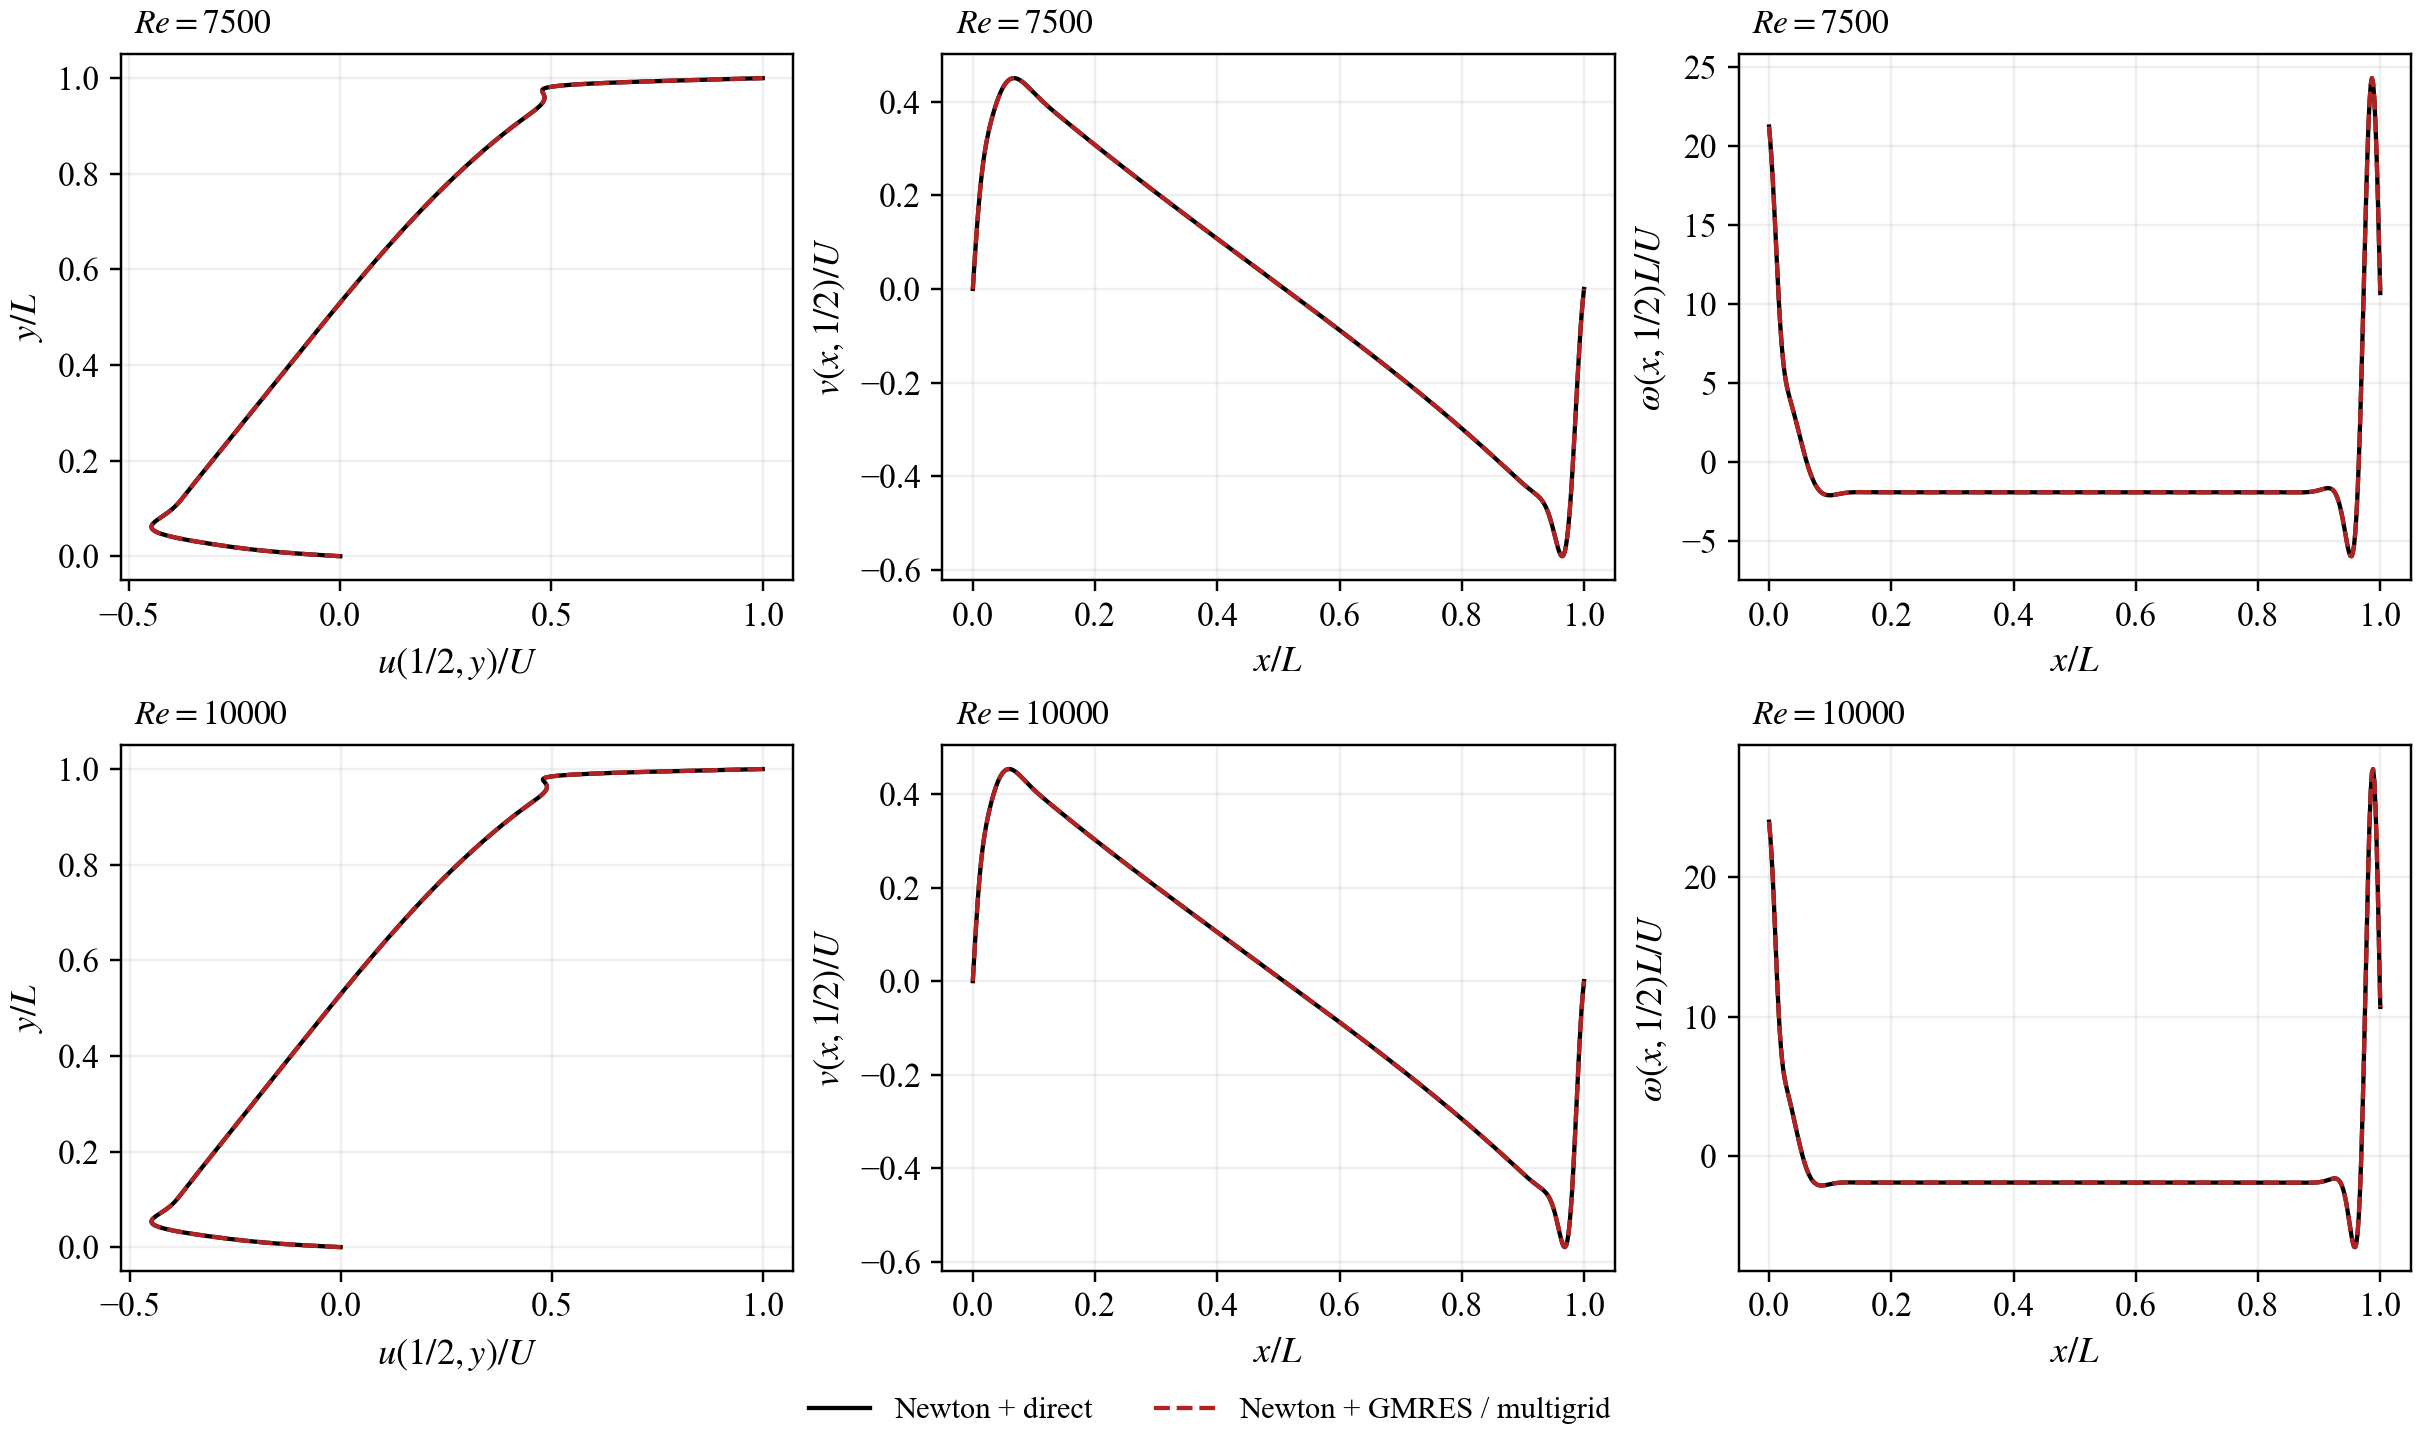

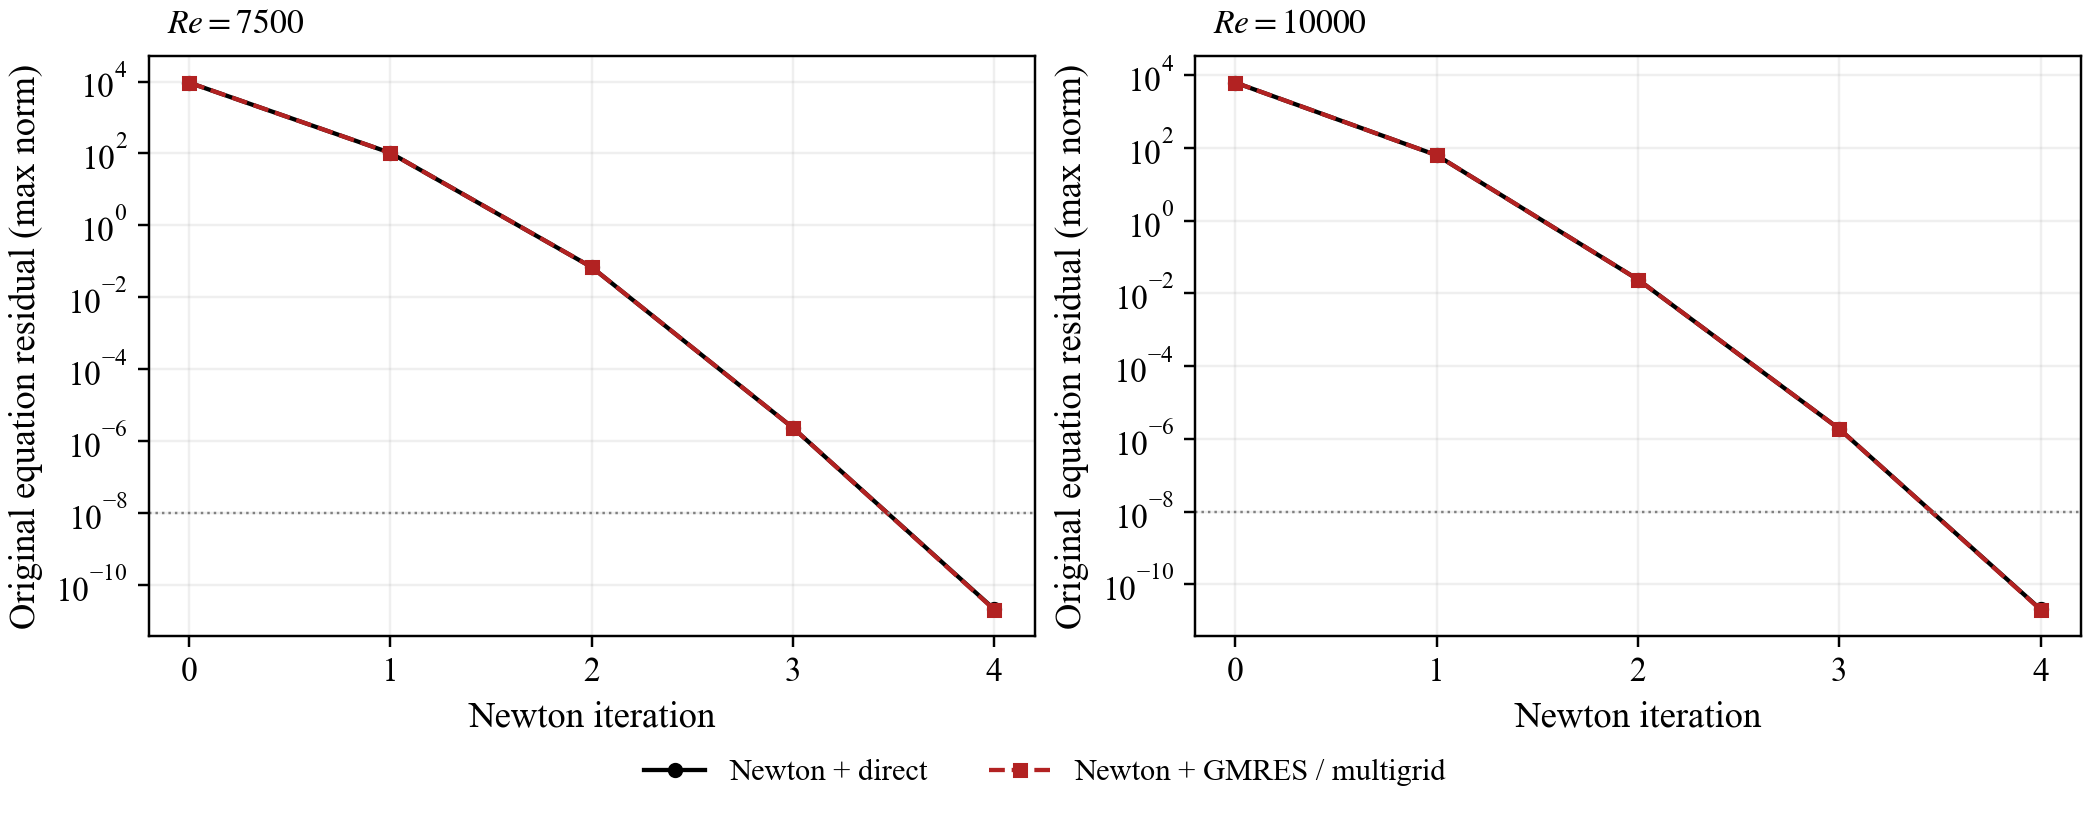

Manifest SHA256: ad6ec8e1ce33e60b123ae7bccf278ed11b3087771d70a396f00e27af4a06ad0e


In [10]:
paired_field_audit = json.loads((BENCH/'paired_fields_audit.json').read_text(encoding='utf-8-sig'))
paired_field_table = pd.DataFrame(paired_field_audit['pairs'])
display(paired_field_table[['nodes', 'scenario', 'repeat',
                           'paired_velocity_relative_l2', 'paired_omega_relative_l2']])
display(Image(filename=str(BENCH/'physical_profiles.png')))
display(Image(filename=str(BENCH/'nonlinear_convergence.png')))
print('Manifest SHA256:', hashlib.sha256((BENCH/'manifest.json').read_bytes()).hexdigest())

### 8.5 Engineering exercises: use the evidence before spending more compute

**F - Make the performance decision numerically.** From `trial_timing`, reproduce
all four warm-case medians and min/max ranges for both methods. Report
$R=T_{\rm MG}/T_{\rm D}$ and the number of repetitions. Explain why the
continuation row is separate and why its single repetition cannot supply a
credible repeat-to-repeat variability estimate. Report the six failed pilot
trials separately; do not average them into successful solve times.

**G - Diagnose the cost and state a testable next idea.** For each warm case,
calculate the ratio of median setup to median total time. Then investigate

$$T_{\rm hyp}(r)=T_{\rm MG}-T_{\rm setup}+rT_{\rm setup},\qquad 0\le r\le1.$$

Here $r$ is the **retained fraction** of setup cost; $1-r$ is the reduction.
Solve for the largest $r$ that would make $T_{\rm hyp}\le T_{\rm D}$ and report
the required percentage reduction for all four cases. Assume other costs stay
fixed only for this calculation. Propose a preconditioner-reuse experiment,
including when to rebuild and how to check the original linear residual.
Reusing factors can increase Krylov work or cause failure: your calculated
headroom is **not a measured speedup** and reuse has not been tested here.

**H - Separate numerical agreement from physical accuracy.** Plot signed
direct-minus-candidate velocity and vorticity differences for the two 513-node
warm cases. Select only entries whose `path` starts with `production/n512/`,
whose `result['repeat'] == 0`, whose `result['scenario']` is `warm7500` or
`warm10000`, and which contain `profiles`. This gives four entries: two methods
for each case. In each `profiles` dictionary, use the stored `y` with `u_center`,
and the stored `x` with `v_center` and `omega_horizontal_center`. Pair the methods
at identical coordinates. Make one three-panel signed-difference figure per Re;
retain the native sample points and the velocity/vorticity units. Compare these
discrepancies with the Lab 7 mesh-sensitivity and Ghia comparisons. Explain why
a difference near machine precision does not make either CFD solution exact
or establish stable high-Re physical flow.

Submit one CSV with timings, ratios, setup fractions, required setup reductions
and sample counts; two signed physical-profile comparisons; and a short
recommendation tied to the measured cost and acceptance gates. Include the
evidence manifest hash. **No additional CFD or training run is required.**

### 8.6 What this experience establishes

For the recorded grids, seeds, precision and hardware, the existing direct solver
is the better production choice. The candidate is retained as a reproducible
experimental implementation, not enabled by default. This result does not rule
out multigrid generally, other smoothers, safe hierarchy reuse, or larger problems.
It is **not** Ghia et al.'s coupled strongly implicit multigrid algorithm. Historical
Ghia timings and hardware prices do not form a controlled speed comparison.
An improved candidate must keep the original acceptance gates, preserve failure
records, freeze tuning on a small pilot, and beat the complete solve cost on fresh
matched cases before replacing the existing method.